# TP2 · Algoritmos de predicción y evaluación de modelos
**Proyecto integrador · Grupo DDL · Producción de dulce de leche**

Este notebook retoma la **pregunta de predicción** del TP1 y la resuelve de forma experimental: baseline, tres algoritmos de regresión, ajuste de hiperparámetros, métricas en entrenamiento y prueba, diagnóstico de ajuste, análisis de residuos, importancia de variables y curva de aprendizaje.

**Versión actualizada:** se reservan diez elaboraciones con identificación única antes de entrenar, validar o evaluar. Para la demostración en Streamlit, el modelo predice sin ver el resultado real.

**Cómo ejecutarlo:** poné el Excel `registro_produccion_LIMPIO (4) (2).xlsx` junto al notebook (o subilo cuando lo pida Colab) y ejecutá todas las celdas en orden.

## A. Definición del marco experimental

### A.1 Problema de predicción
**Pregunta:** ¿se puede estimar, *antes de cerrar la elaboración*, cuántos puntos porcentuales (p.p.) se apartará el rendimiento obtenido del rendimiento esperado de su receta?

- **Variable objetivo (continua):** `DESVIO_PP = (RENDIMIENTO % − RENDIMIENTO ESPERADO) × 100`. Positivo = rinde más de lo esperado; negativo = rinde menos.
- **Relevancia práctica:** el rendimiento esperado ya está fijado por la receta. Lo que interesa a la planta es anticipar el *apartamiento* para decidir dónde controlar primero (en el TP1, el 55,3 % de las elaboraciones quedó por debajo de lo esperado y la Masa 4 llegó a 75,3 %).
- **Por qué desvío y no rendimiento:** en el TP1 vimos que el tipo de masa explica casi todo el rendimiento (R² ≈ 0,98 con solo el promedio por masa). Predecir el rendimiento sería trivial; el desvío es la parte que la receta **no** explica.

### A.2 Variables predictoras (y exclusiones) según los hallazgos del TP1
| Incluidas | Justificación (TP1) |
|---|---|
| `MASA` | Ordena el costo, los insumos y el rendimiento (EDA preguntas 4 y 6). Se codifica *one-hot*. |
| `LITROS DE LECHE` | Tamaño de la elaboración. |
| Azúcar, suero, bicarbonato, L.P.D. **por litro** | Insumos normalizados por litro para comparar elaboraciones de distinto tamaño; la pregunta 5 mostró desvíos contra la receta concentrados en L.P.D. |
| `MATERIA GRASA`, `PROTEINAS` | Composición de la leche; varía más entre meses que entre silos (pregunta 10). |

| Excluidas | Motivo |
|---|---|
| `TOTAL KG OBTENIDOS`, `RENDIMIENTO %` | Contienen el resultado (**fuga de información**). |
| `Nº SILO` | Los silos entregan leche casi idéntica (pregunta 10). |
| Columnas de acidez | No se sabe qué mide cada una (pregunta 10). |
| Precios (`COSTO ...`) | Ajustados por un factor y casi constantes dentro de cada masa (pregunta 4). |
| Fecha | Se usa solo para ordenar y particionar en el tiempo, no como predictor. |

> **Supuesto a confirmar con la empresa:** que insumos y composición de la leche se conozcan antes de cerrar la elaboración.

In [1]:
# ---------- Importaciones y configuración ----------
from pathlib import Path
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from scipy import stats
from IPython.display import display
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings('ignore')
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 30)
SEMILLA = 42                      # semilla fija: reproducibilidad de los modelos con aleatoriedad
np.random.seed(SEMILLA)
FIG = Path('figuras_TP2'); FIG.mkdir(exist_ok=True)
def etq(n):
    return {'Base: promedio por masa': 'Base:\nprom. masa', 'Base: regresión lineal': 'Base:\nreg. lineal', 'Árbol de decisión': 'Árbol de\ndecisión'}.get(n, n)
def caja(ax, datos, etiquetas, **kw):
    '''Boxplot compatible con distintas versiones de matplotlib (evita el argumento labels/tick_labels).'''
    ax.boxplot(datos, **kw); ax.set_xticks(range(1, len(datos) + 1)); ax.set_xticklabels(etiquetas)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25, 'axes.spines.top': False, 'axes.spines.right': False})

# ---------- Carga de datos ----------
ARCHIVO = 'registro_produccion_LIMPIO.xlsx'
ruta = next((p for p in [Path(ARCHIVO), Path('/mnt/data') / ARCHIVO] if p.exists()), None)
if ruta is None:                  # Google Colab: pedir el archivo
    from google.colab import files
    print('Subí el Excel para continuar:'); files.upload(); ruta = Path(ARCHIVO)
df = pd.read_excel(ruta, sheet_name='Registro Produccion')
df.columns = df.columns.str.strip()
print('Dataset original:', df.shape)

Dataset original: (1111, 79)


### A.3 Limpieza (mismos criterios que el TP1) y construcción de la variable objetivo
El enunciado pide usar el dataset del TP1 *con la limpieza ya aplicada*. Se reaplican sus criterios: se excluyen las corridas de prueba (**Masa 8**, rendimiento esperado = 0) y el registro con rendimiento imposible (**144 % en Masa 4**). Los demás registros se conservan.

In [2]:
d = df.copy()
num_cols = ['LITROS DE LECHE','AZUCAR','SUERO','BICARBONATO','L.P.D','MATERIA GRASA','PROTEINAS','RENDIMIENTO %','RENDIMIENTO ESPERADO']
for c in num_cols:
    d[c] = pd.to_numeric(d[c], errors='coerce')
d['FECHA ELABORACION'] = pd.to_datetime(d['FECHA ELABORACION'], errors='coerce')

# --- Criterios de exclusión (documentados) ---
excl_prueba = d['MASA'].eq('MASA 8') | ~d['RENDIMIENTO ESPERADO'].gt(0)          # corridas de prueba
excl_raro   = d['RENDIMIENTO %'].gt(1.2) & d['MASA'].ne('MASA 7')                   # rendimiento imposible (144 %)
excl_nan    = d[['RENDIMIENTO %','LITROS DE LECHE','MASA','FECHA ELABORACION']].isna().any(axis=1) | ~d['LITROS DE LECHE'].gt(0)
valido = ~(excl_prueba | excl_raro | excl_nan)
print(f'Registros originales: {len(d)} | corridas de prueba: {int(excl_prueba.sum())} | rendimiento imposible: {int((excl_raro & ~excl_prueba).sum())} | sin datos básicos: {int((excl_nan & ~excl_prueba & ~excl_raro).sum())}')
d = d.loc[valido].copy()

# --- Variable objetivo y predictoras ---
d['DESVIO_PP'] = (d['RENDIMIENTO %'] - d['RENDIMIENTO ESPERADO']) * 100
for c in ['AZUCAR','SUERO','BICARBONATO','L.P.D']:
    d[c + ' por litro'] = d[c] / d['LITROS DE LECHE']
VARIABLES = ['MASA','LITROS DE LECHE','AZUCAR por litro','SUERO por litro','BICARBONATO por litro','L.P.D por litro','MATERIA GRASA','PROTEINAS']
NUMERICAS = [c for c in VARIABLES if c != 'MASA']
d = d.sort_values(['FECHA ELABORACION','Nº LOTE DDL'], kind='stable').reset_index(drop=True)
print('Registros válidos:', len(d))
print('\nValores faltantes en las predictoras:'); print(d[VARIABLES].isna().sum().to_string())
print('\nDistribución de la variable objetivo (p.p.):'); print(d['DESVIO_PP'].describe().round(2).to_string())

Registros originales: 1111 | corridas de prueba: 6 | rendimiento imposible: 1 | sin datos básicos: 0
Registros válidos: 1104

Valores faltantes en las predictoras:
MASA                      0
LITROS DE LECHE           0
AZUCAR por litro          0
SUERO por litro           0
BICARBONATO por litro     0
L.P.D por litro           1
MATERIA GRASA            25
PROTEINAS                25

Distribución de la variable objetivo (p.p.):
count    1104.00
mean       -0.69
std         3.34
min       -63.90
25%        -2.12
50%        -0.90
75%         0.90
max        17.10


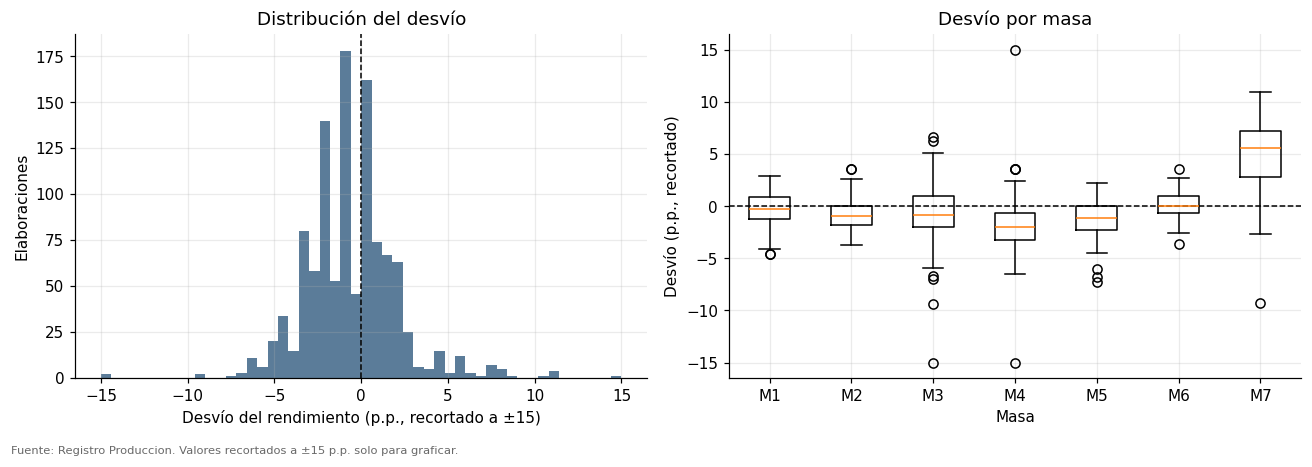

Extremos (|desvío| > 25 p.p.):
    FECHA ELABORACION    MASA  RENDIMIENTO %  RENDIMIENTO ESPERADO  DESVIO_PP
388        2025-08-14  MASA 4          0.225                 0.864      -63.9
515        2025-10-06  MASA 3          0.567                 0.837      -27.0


In [3]:
# Visualización de la variable objetivo: distribución global y por masa
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].hist(d['DESVIO_PP'].clip(-15, 15), bins=50, color='#5B7C99')
ax[0].axvline(0, color='black', ls='--', lw=1)
ax[0].set_xlabel('Desvío del rendimiento (p.p., recortado a ±15)'); ax[0].set_ylabel('Elaboraciones'); ax[0].set_title('Distribución del desvío')
orden = sorted(d['MASA'].unique())
caja(ax[1], [d.loc[d['MASA'] == m, 'DESVIO_PP'].clip(-15, 15) for m in orden], [m.replace('MASA ', 'M') for m in orden])
ax[1].axhline(0, color='black', ls='--', lw=1); ax[1].set_xlabel('Masa'); ax[1].set_ylabel('Desvío (p.p., recortado)'); ax[1].set_title('Desvío por masa')
fig.text(.01, .005, 'Fuente: Registro Produccion. Valores recortados a ±15 p.p. solo para graficar.', fontsize=7.5, color='dimgray')
plt.tight_layout(rect=(0, .03, 1, 1)); plt.savefig(FIG / 'fig0_objetivo.png', dpi=150); plt.show()
print('Extremos (|desvío| > 25 p.p.):')
print(d.loc[d['DESVIO_PP'].abs() > 25, ['FECHA ELABORACION','MASA','RENDIMIENTO %','RENDIMIENTO ESPERADO','DESVIO_PP']].round(3).to_string())

### A.4 Partición temporal y demostración reservada
Se apartan **diez elaboraciones de identificador único**, provenientes de los registros más recientes. Si una combinación de fecha, masa y número de lote aparece repetida, **no se usa para la demostración**, para evitar filtración de un duplicado a entrenamiento o prueba.

Los restantes datos siguen el criterio del TP2 original: **70 % más antiguos para entrenamiento** y **30 % más recientes para prueba**, con validación cruzada temporal de cinco pliegues solo en entrenamiento. Las diez reservadas no intervienen en ninguna métrica ni en la selección del modelo.

In [4]:
# Reservar diez elaboraciones completas y de clave única antes de todo entrenamiento.
# No se sortean del conjunto de prueba: son una tercera partición completamente independiente.
CLAVES = ['FECHA ELABORACION', 'Nº LOTE DDL', 'MASA']
frecuencia_claves = d.groupby(CLAVES, dropna=False)['MASA'].transform('size')
candidatas = d.loc[frecuencia_claves.eq(1)]
assert len(candidatas) >= 10, 'No hay suficientes elaboraciones con identificador único'
indices_reserva = candidatas.tail(10).index
reservado = d.loc[indices_reserva].sort_values(['FECHA ELABORACION','Nº LOTE DDL'], kind='stable').copy()
desarrollo = d.drop(index=indices_reserva).sort_values(['FECHA ELABORACION','Nº LOTE DDL'],kind='stable').copy()
assert len(reservado)==10 and len(set(indices_reserva)&set(desarrollo.index))==0
assert not reservado.duplicated(CLAVES).any()
# No queda NINGUNA copia del mismo lote/fecha/masa dentro de desarrollo.
claves_reservadas = {tuple(row) for row in reservado[CLAVES].itertuples(index=False,name=None)}
claves_desarrollo = {tuple(row) for row in desarrollo[CLAVES].itertuples(index=False,name=None)}
assert claves_reservadas.isdisjoint(claves_desarrollo)

k = int(round(len(desarrollo)*0.70))
train, test = desarrollo.iloc[:k].copy(), desarrollo.iloc[k:].copy()
assert train['FECHA ELABORACION'].max() <= test['FECHA ELABORACION'].min()
print(f'Entrenamiento: {len(train)} ({len(train)/len(desarrollo):.1%}) | {train["FECHA ELABORACION"].min().date()} a {train["FECHA ELABORACION"].max().date()}')
print(f'Prueba:        {len(test)} ({len(test)/len(desarrollo):.1%}) | {test["FECHA ELABORACION"].min().date()} a {test["FECHA ELABORACION"].max().date()}')
print('Reservadas:    ',len(reservado),'(diez elaboraciones sin duplicados en desarrollo)')
display(reservado[CLAVES + ['DESVIO_PP']].assign(DESVIO_PP=lambda x:x.DESVIO_PP.round(3)).reset_index(drop=True))
Xtr, ytr, Xte, yte = train[VARIABLES], train['DESVIO_PP'], test[VARIABLES], test['DESVIO_PP']
cv = TimeSeriesSplit(n_splits=5)

Entrenamiento: 766 (70.0%) | 2025-01-02 a 2026-03-09
Prueba:        328 (30.0%) | 2026-03-09 a 2026-08-19
Reservadas:     10 (diez elaboraciones sin duplicados en desarrollo)


,FECHA ELABORACION,Nº LOTE DDL,MASA,DESVIO_PP
0,2026-08-12,9,MASA 2,-0.900
1,2026-08-13,10,MASA 3,-2.484
2,2026-08-13,11,MASA 3,2.700
3,2026-08-13,12,MASA 2,-1.800
4,2026-08-14,13,MASA 1,-2.340
5,2026-08-14,15,MASA 2,-0.900
6,2026-08-15,16,MASA 2,-1.800
7,2026-08-18,17,MASA 1,-0.450
8,2026-08-18,18,MASA 1,-0.450
9,2026-08-18,19,MASA 3,6.300


### A.5 Líneas base (baselines)
1. **Promedio por masa:** predice, para cada elaboración, el desvío medio histórico de su masa (calculado solo con entrenamiento). Es el referente natural porque la masa es lo que más explica en el TP1.
2. **Regresión lineal múltiple:** el baseline que recomienda la consigna, con las mismas variables y preprocesamiento que los modelos.

Cualquier modelo más complejo debe superar a ambos para justificar su complejidad.

## B. Implementación de los modelos

**Preprocesamiento (dentro de un `Pipeline`, aprendido solo con entrenamiento):** imputación por mediana en numéricas (la moda en `MASA`), *one-hot encoding* de `MASA` y **estandarización** solo para los modelos lineales (Ridge y regresión lineal), porque la penalización y los coeficientes dependen de las unidades; árboles y *Random Forest* no la necesitan.

| Algoritmo | Por qué | Hiperparámetros explorados |
|---|---|---|
| Regresión **Ridge** (L2) | Insumos por litro correlacionados entre sí; L2 estabiliza coeficientes. | `alpha` ∈ {0,1; 1; 10; 100} |
| **Árbol de decisión** | Captura no linealidades e interacciones con la masa; interpretable. | `max_depth` ∈ {3; 5; 8; sin límite}, `min_samples_leaf` ∈ {2; 5; 10} |
| **Random Forest** | Promedia muchos árboles: reduce varianza, robusto a extremos. | `n_estimators` ∈ {100; 200}, `max_depth` ∈ {5; 10; sin límite}, `min_samples_leaf` ∈ {2; 5; 10} |

Búsqueda con `GridSearchCV` sobre el entrenamiento, criterio **MAE** (robusto a valores atípicos, que existen en este dataset).

In [5]:
# ---------- Preprocesamiento y baselines ----------
def preprocesar(escalar=False):
    pasos = [('imputar', SimpleImputer(strategy='median'))]
    if escalar: pasos.append(('escalar', StandardScaler()))
    return ColumnTransformer([
        ('num', Pipeline(pasos), NUMERICAS),
        ('masa', Pipeline([('imputar', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))]), ['MASA'])])

class PromedioPorMasa(BaseEstimator, RegressorMixin):
    '''Baseline: predice el desvío medio de entrenamiento de la masa de cada elaboración.'''
    def fit(self, X, y):
        self.medias_ = pd.Series(np.asarray(y), index=X['MASA'].values).groupby(level=0).mean()
        self.global_ = float(np.mean(y)); return self
    def predict(self, X):
        return X['MASA'].map(self.medias_).fillna(self.global_).to_numpy()

baseline_masa = PromedioPorMasa().fit(Xtr, ytr)
baseline_lineal = Pipeline([('preparar', preprocesar(True)), ('modelo', LinearRegression())]).fit(Xtr, ytr)

# ---------- Algoritmos con hiperparámetros por defecto (para medir la mejora de la búsqueda) ----------
defecto = {
    'Ridge': Pipeline([('preparar', preprocesar(True)), ('modelo', Ridge())]),
    'Árbol de decisión': Pipeline([('preparar', preprocesar(False)), ('modelo', DecisionTreeRegressor(random_state=SEMILLA))]),
    'Random Forest': Pipeline([('preparar', preprocesar(False)), ('modelo', RandomForestRegressor(random_state=SEMILLA, n_jobs=1))])}
# ---------- Búsqueda de hiperparámetros ----------
grillas = {
    'Ridge': (Ridge(), {'modelo__alpha': [0.1, 1, 10, 100]}, True),
    'Árbol de decisión': (DecisionTreeRegressor(random_state=SEMILLA), {'modelo__max_depth': [3, 5, 8, None], 'modelo__min_samples_leaf': [2, 5, 10]}, False),
    'Random Forest': (RandomForestRegressor(random_state=SEMILLA, n_jobs=1), {'modelo__n_estimators': [100, 200], 'modelo__max_depth': [5, 10, None], 'modelo__min_samples_leaf': [2, 5, 10]}, False)}
busquedas = {}
for nombre, (est, grilla, escalar) in grillas.items():
    gs = GridSearchCV(Pipeline([('preparar', preprocesar(escalar)), ('modelo', est)]), grilla, cv=cv,
                      scoring='neg_mean_absolute_error', n_jobs=-1, refit=True)
    busquedas[nombre] = gs.fit(Xtr, ytr)
    print(f'{nombre}: mejores parámetros = {gs.best_params_} | MAE CV = {-gs.best_score_:.3f} p.p.')

Ridge: mejores parámetros = {'modelo__alpha': 10} | MAE CV = 1.909 p.p.


Árbol de decisión: mejores parámetros = {'modelo__max_depth': 3, 'modelo__min_samples_leaf': 10} | MAE CV = 1.925 p.p.


Random Forest: mejores parámetros = {'modelo__max_depth': 10, 'modelo__min_samples_leaf': 10, 'modelo__n_estimators': 200} | MAE CV = 1.923 p.p.


## C. Evaluación y comparación
Métricas de regresión: **MSE, RMSE, MAE, R²** (obligatorias) y **R² ajustado** (complementaria). **MAPE no se usa:** el desvío está centrado en cero (mediana ≈ −0,9 p.p.) y el cociente por el valor real explotaría con valores cercanos a 0.

In [6]:
modelos = {'Base: promedio por masa': baseline_masa, 'Base: regresión lineal': baseline_lineal}
modelos.update({n: gs.best_estimator_ for n, gs in busquedas.items()})
N_PRED = {'Base: promedio por masa': 6}   # 6 contrastes (7 masas)

def n_predictores(m):
    if isinstance(m, Pipeline): return m.named_steps['preparar'].transform(Xtr.head(5)).shape[1]
    return N_PRED[[k for k, v in modelos.items() if v is m][0]]

def metricas(y, p, n_pred):
    n = len(y); r2 = r2_score(y, p); mse = mean_squared_error(y, p)
    return {'MSE': mse, 'RMSE': np.sqrt(mse), 'MAE': mean_absolute_error(y, p), 'R²': r2, 'R² ajustado': 1 - (1 - r2) * (n - 1) / (n - n_pred - 1)}

filas = []; pred_tr, pred_te = {}, {}
for nombre, m in modelos.items():
    pred_tr[nombre], pred_te[nombre] = m.predict(Xtr), m.predict(Xte)
    p = n_predictores(m)
    for conj, y, pr in [('Entrenamiento', ytr, pred_tr[nombre]), ('Prueba', yte, pred_te[nombre])]:
        filas.append({'Modelo': nombre, 'Conjunto': conj, **metricas(y, pr, p)})
tabla = pd.DataFrame(filas)
cv_mae = {n: -gs.best_score_ for n, gs in busquedas.items()}
print('TABLA COMPARATIVA CONSOLIDADA (desvío en p.p.; menor error y mayor R² es mejor)')
display(tabla.round(3))
ancha = tabla.pivot(index='Modelo', columns='Conjunto', values=['MAE', 'RMSE', 'R²']).round(3)
ancha = ancha.loc[list(modelos)]
ancha['MAE CV (entren.)'] = pd.Series(cv_mae).round(3)
print('\nVISTA RESUMIDA'); display(ancha)
tabla.to_csv(FIG / 'tabla_metricas.csv', index=False)

TABLA COMPARATIVA CONSOLIDADA (desvío en p.p.; menor error y mayor R² es mejor)


,Modelo,Conjunto,MSE,RMSE,MAE,R²,R² ajustado
0,Base: promedio por masa,Entrenamiento,10.788,3.285,1.759,0.207,0.201
1,Base: promedio por masa,Prueba,5.015,2.239,1.651,0.057,0.039
2,Base: regresión lineal,Entrenamiento,10.562,3.250,1.698,0.224,0.210
3,Base: regresión lineal,Prueba,14.615,3.823,2.092,-1.749,-1.872
4,Ridge,Entrenamiento,10.630,3.260,1.712,0.219,0.204
5,Ridge,Prueba,5.122,2.263,1.719,0.036,-0.007
6,Árbol de decisión,Entrenamiento,10.474,3.236,1.738,0.230,0.216
7,Árbol de decisión,Prueba,5.218,2.284,1.711,0.018,-0.025
8,Random Forest,Entrenamiento,8.810,2.968,1.481,0.353,0.341
9,Random Forest,Prueba,5.268,2.295,1.732,0.009,-0.035



VISTA RESUMIDA


MAE                 RMSE                   R²        MAE CV (entren.)
Conjunto                Entrenamiento Prueba Entrenamiento Prueba Entrenamiento Prueba                 
Modelo                                                                                                 
Base: promedio por masa         1.759  1.651         3.285  2.239         0.207  0.057              NaN
Base: regresión lineal          1.698  2.092         3.250  3.823         0.224 -1.749              NaN
Ridge                           1.712  1.719         3.260  2.263         0.219  0.036            1.909
Árbol de decisión               1.738  1.711         3.236  2.284         0.230  0.018            1.925
Random Forest                   1.481  1.732         2.968  2.295         0.353  0.009            1.923

In [7]:
# Mejora obtenida por la búsqueda de hiperparámetros (extensión): defecto vs ajustado
filas = []
for nombre, m0 in defecto.items():
    m0 = clone(m0).fit(Xtr, ytr)
    filas.append({'Modelo': nombre, 'MAE prueba (defecto)': mean_absolute_error(yte, m0.predict(Xte)),
                  'MAE prueba (ajustado)': mean_absolute_error(yte, modelos[nombre].predict(Xte)),
                  'Mejores parámetros': str(busquedas[nombre].best_params_)})
mejora = pd.DataFrame(filas); mejora['Mejora (p.p.)'] = mejora['MAE prueba (defecto)'] - mejora['MAE prueba (ajustado)']
display(mejora.round(3))

,Modelo,MAE prueba (defecto),MAE prueba (ajustado),Mejores parámetros,Mejora (p.p.)
0,Ridge,1.697,1.719,{'modelo__alpha': 10},-0.022
1,Árbol de decisión,2.185,1.711,"{'modelo__max_depth': 3, 'modelo__min_samples_...",0.474
2,Random Forest,1.847,1.732,"{'modelo__max_depth': 10, 'modelo__min_samples...",0.115


### Diagnóstico de sobreajuste (overfitting) y subajuste (underfitting)
Se compara el desempeño en entrenamiento y en prueba. Señales: **sobreajuste** = error de entrenamiento mucho menor que el de prueba; **subajuste** = error alto y R² bajo *en ambos* conjuntos (el modelo no captura la señal).

In [8]:
filas = []
for nombre in modelos:
    a = tabla[(tabla.Modelo == nombre) & (tabla.Conjunto == 'Entrenamiento')].iloc[0]; b = tabla[(tabla.Modelo == nombre) & (tabla.Conjunto == 'Prueba')].iloc[0]
    brecha = b['MAE'] - a['MAE']; brecha_r2 = a['R²'] - b['R²']
    if brecha > 0.15 * a['MAE'] or brecha_r2 > 0.25: diag = 'sobreajuste / alta varianza (rinde mucho peor en prueba que en entrenamiento)'
    elif a['R²'] < 0.30 and b['R²'] < 0.30: diag = 'subajuste / alto sesgo (R² bajo en ambos conjuntos)'
    else: diag = 'ajuste razonable'
    filas.append({'Modelo': nombre, 'MAE entren.': a['MAE'], 'MAE prueba': b['MAE'], 'Brecha MAE (prueba − entren.)': brecha, 'Caída de R² (entren. − prueba)': brecha_r2, 'R² entren.': a['R²'], 'R² prueba': b['R²'], 'Diagnóstico': diag})
diagnostico = pd.DataFrame(filas); display(diagnostico.round(3))
print('Nota: el RMSE de entrenamiento incluye los extremos de 2025 (p. ej. -63,9 p.p.), por eso puede superar al de prueba; el MAE es menos sensible.')

,Modelo,MAE entren.,MAE prueba,Brecha MAE (prueba − entren.),Caída de R² (entren. − prueba),R² entren.,R² prueba,Diagnóstico
0,Base: promedio por masa,1.759,1.651,-0.108,0.151,0.207,0.057,subajuste / alto sesgo (R² bajo en ambos conju...
1,Base: regresión lineal,1.698,2.092,0.395,1.973,0.224,-1.749,sobreajuste / alta varianza (rinde mucho peor ...
2,Ridge,1.712,1.719,0.007,0.183,0.219,0.036,subajuste / alto sesgo (R² bajo en ambos conju...
3,Árbol de decisión,1.738,1.711,-0.026,0.212,0.230,0.018,subajuste / alto sesgo (R² bajo en ambos conju...
4,Random Forest,1.481,1.732,0.251,0.344,0.353,0.009,sobreajuste / alta varianza (rinde mucho peor ...


Nota: el RMSE de entrenamiento incluye los extremos de 2025 (p. ej. -63,9 p.p.), por eso puede superar al de prueba; el MAE es menos sensible.


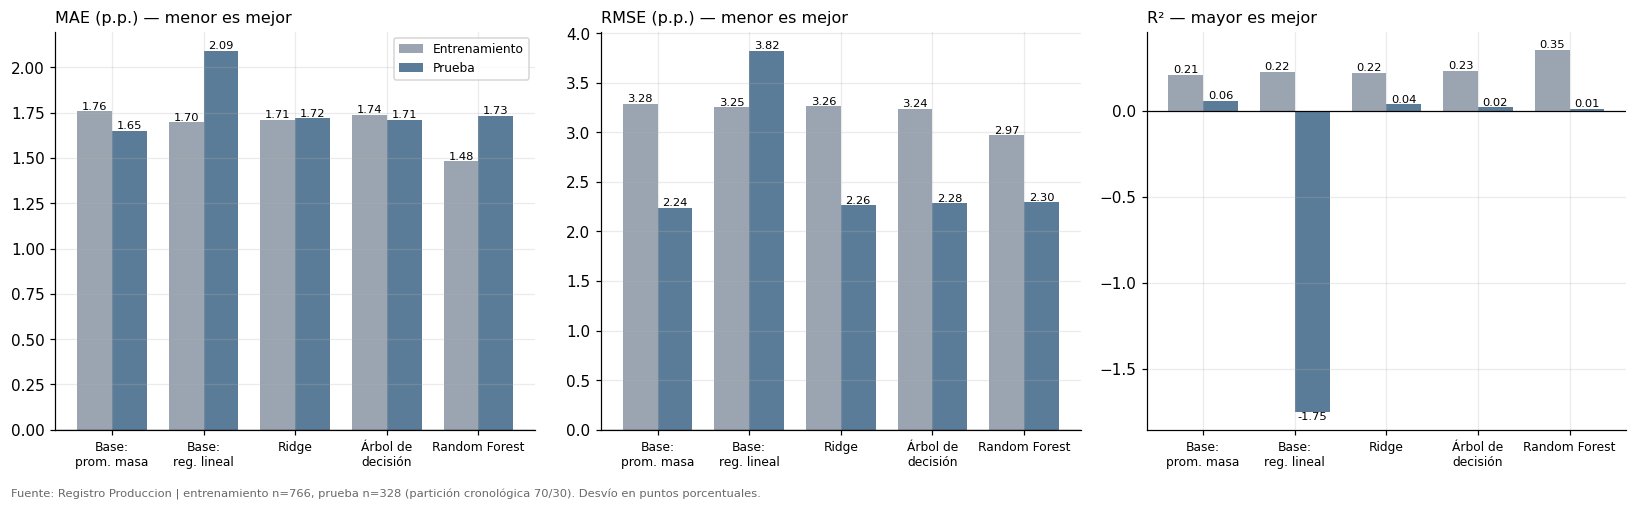

In [9]:
# ---------- Visualización 1: métricas por modelo, entrenamiento vs prueba ----------
nombres = list(modelos); x = np.arange(len(nombres)); w = .38
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
for a, met, tit in zip(ax, ['MAE', 'RMSE', 'R²'], ['MAE (p.p.) — menor es mejor', 'RMSE (p.p.) — menor es mejor', 'R² — mayor es mejor']):
    v1 = [tabla[(tabla.Modelo == n) & (tabla.Conjunto == 'Entrenamiento')][met].iloc[0] for n in nombres]
    v2 = [tabla[(tabla.Modelo == n) & (tabla.Conjunto == 'Prueba')][met].iloc[0] for n in nombres]
    b1 = a.bar(x - w/2, v1, w, label='Entrenamiento', color='#9AA5B1'); b2 = a.bar(x + w/2, v2, w, label='Prueba', color='#5B7C99')
    for bb in list(b1) + list(b2): a.text(bb.get_x() + bb.get_width()/2, bb.get_height(), f'{bb.get_height():.2f}', ha='center', va='bottom' if bb.get_height() >= 0 else 'top', fontsize=7.5)
    a.set_xticks(x); a.set_xticklabels([etq(n) for n in nombres], fontsize=8)
    a.set_title(tit, fontsize=10.5, loc='left'); a.axhline(0, color='black', lw=.8)
ax[0].legend(fontsize=8)
fig.text(.01, .005, f'Fuente: Registro Produccion | entrenamiento n={len(train)}, prueba n={len(test)} (partición cronológica 70/30). Desvío en puntos porcentuales.', fontsize=7.5, color='dimgray')
plt.tight_layout(rect=(0, .03, 1, 1)); plt.savefig(FIG / 'fig1_metricas.png', dpi=150); plt.show()

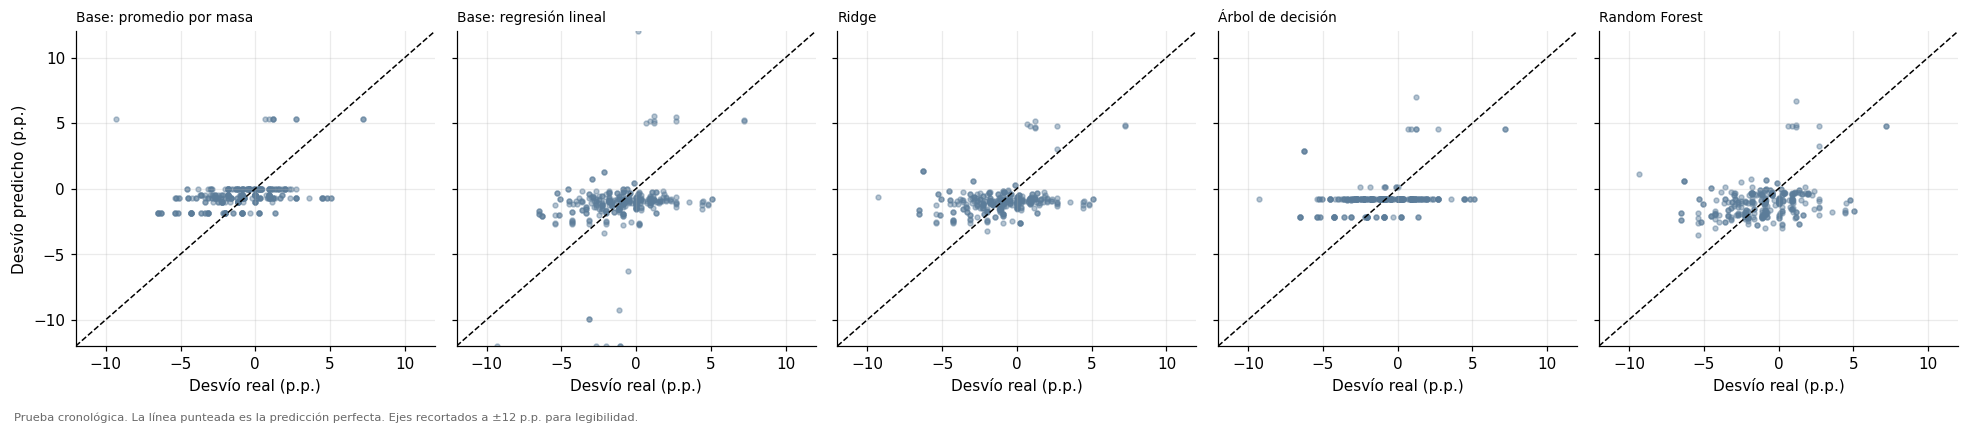

In [10]:
# ---------- Visualización 2: predicho vs real en prueba, un panel por modelo ----------
fig, axs = plt.subplots(1, len(nombres), figsize=(3.6 * len(nombres), 3.9), sharex=True, sharey=True)
lim = [-12, 12]
for a, n in zip(axs, nombres):
    a.scatter(yte, np.clip(pred_te[n], *lim), s=10, alpha=.45, color='#5B7C99'); a.plot(lim, lim, '--', color='black', lw=1)
    a.set_xlim(lim); a.set_ylim(lim); a.set_title(n.replace('Base: ', 'Base: '), fontsize=9, loc='left'); a.set_xlabel('Desvío real (p.p.)')
axs[0].set_ylabel('Desvío predicho (p.p.)')
fig.text(.01, .005, 'Prueba cronológica. La línea punteada es la predicción perfecta. Ejes recortados a ±12 p.p. para legibilidad.', fontsize=7.5, color='dimgray')
plt.tight_layout(rect=(0, .03, 1, 1)); plt.savefig(FIG / 'fig2_real_vs_predicho.png', dpi=150); plt.show()

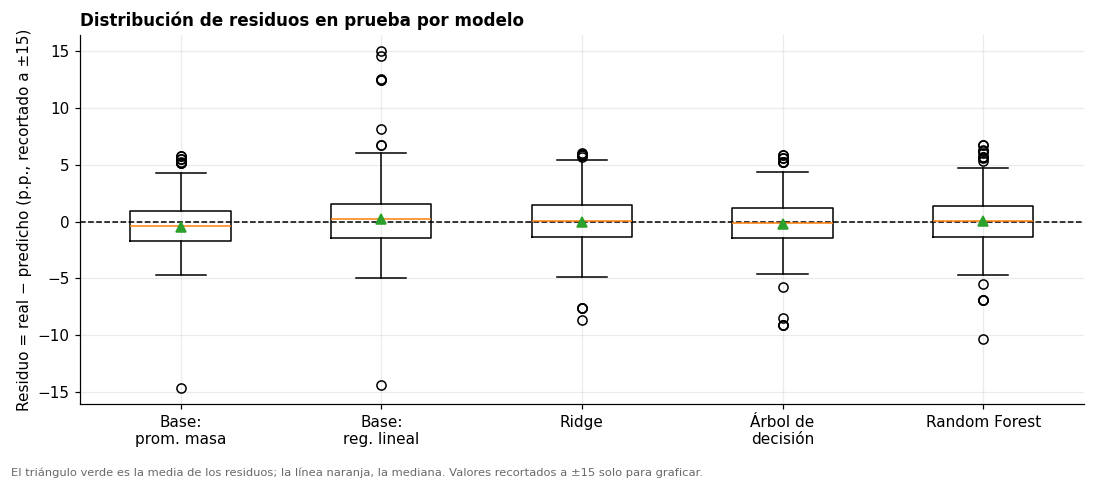

In [11]:
# ---------- Visualización 3: distribución de errores (residuos) por modelo ----------
res_te = {n: yte.to_numpy() - pred_te[n] for n in nombres}
fig, ax = plt.subplots(figsize=(10, 4.4))
caja(ax, [np.clip(res_te[n], -15, 15) for n in nombres], [etq(n) for n in nombres], showmeans=True)
ax.axhline(0, color='black', ls='--', lw=1); ax.set_ylabel('Residuo = real − predicho (p.p., recortado a ±15)')
ax.set_title('Distribución de residuos en prueba por modelo', loc='left', fontsize=11, fontweight='bold')
fig.text(.01, .005, 'El triángulo verde es la media de los residuos; la línea naranja, la mediana. Valores recortados a ±15 solo para graficar.', fontsize=7.5, color='dimgray')
plt.tight_layout(rect=(0, .03, 1, 1)); plt.savefig(FIG / 'fig3_residuos_boxplot.png', dpi=150); plt.show()

### Selección del modelo
Criterio fijado **antes** de mirar la prueba: el algoritmo (Ridge, árbol o Random Forest) con **menor MAE de validación cruzada temporal** en entrenamiento. La prueba sirve solo para verificar la generalización y no para elegir.

In [12]:
algoritmos = list(busquedas)
elegido = min(algoritmos, key=lambda n: cv_mae[n])
mae_te = {n: mean_absolute_error(yte, pred_te[n]) for n in nombres}
print('MAE de validación cruzada (entrenamiento):', {n: round(v, 3) for n, v in cv_mae.items()})
print('MODELO ELEGIDO por MAE CV:', elegido)
print(f'MAE prueba del elegido: {mae_te[elegido]:.3f} | baseline promedio por masa: {mae_te["Base: promedio por masa"]:.3f} | baseline lineal: {mae_te["Base: regresión lineal"]:.3f}')
mejor_en_prueba = min(nombres, key=lambda n: mae_te[n])
print('Mejor MAE en prueba (solo informativo):', mejor_en_prueba, round(mae_te[mejor_en_prueba], 3))
dif = mae_te['Base: promedio por masa'] - mae_te[elegido]
print(f'Mejora del elegido sobre el promedio por masa: {dif:+.3f} p.p. ({dif / mae_te["Base: promedio por masa"]:+.1%})')
# ¿Cambia la elección según la métrica? (pregunta 1 del cuestionario)
pt = tabla[tabla.Conjunto == 'Prueba'].set_index('Modelo').loc[algoritmos]
print('\nMejor algoritmo en prueba según cada métrica:', {m: (pt[m].idxmax() if m == 'R²' else pt[m].idxmin()) for m in ['MAE', 'RMSE', 'R²']})

MAE de validación cruzada (entrenamiento): {'Ridge': np.float64(1.909), 'Árbol de decisión': np.float64(1.925), 'Random Forest': np.float64(1.923)}
MODELO ELEGIDO por MAE CV: Ridge
MAE prueba del elegido: 1.719 | baseline promedio por masa: 1.651 | baseline lineal: 2.092
Mejor MAE en prueba (solo informativo): Base: promedio por masa 1.651
Mejora del elegido sobre el promedio por masa: -0.068 p.p. (-4.1%)

Mejor algoritmo en prueba según cada métrica: {'MAE': 'Árbol de decisión', 'RMSE': 'Ridge', 'R²': 'Ridge'}


### Análisis de residuos del modelo elegido
Distribución, normalidad, residuos contra predichos (homocedasticidad), residuos por masa y autocorrelación temporal.

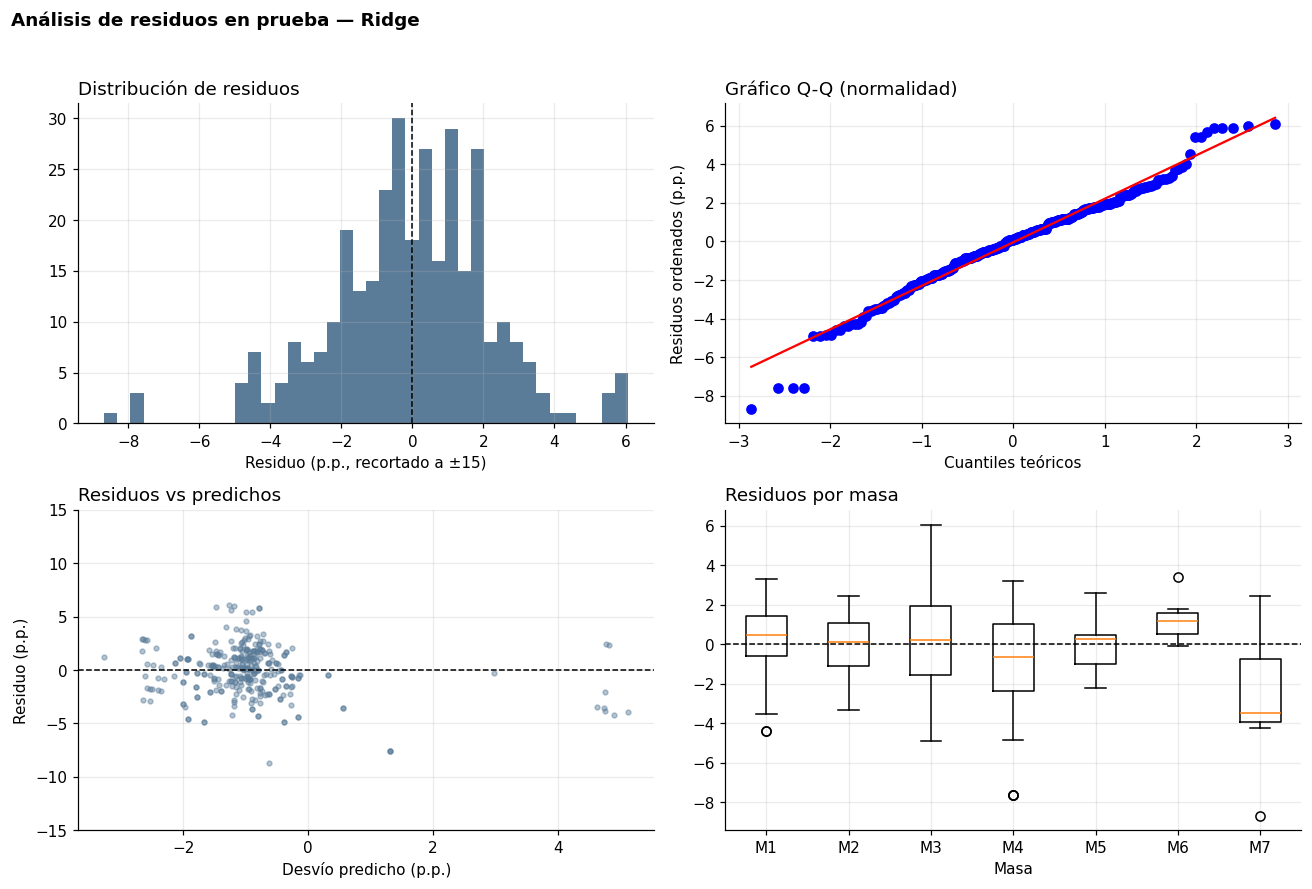

Normalidad (Shapiro-Wilk): W=0.979, p=1.20e-04 -> se rechaza normalidad
Asimetría=-0.34 | curtosis en exceso=1.25 (colas pesadas si >> 0)
Homocedasticidad: Spearman(|residuo|, predicho) rho=0.101, p=0.068
Varianza de residuos entre masas (Levene): estadístico=7.49, p=0.0000
Autocorrelación temporal (Durbin-Watson, ~2 = sin autocorrelación): 1.63
Residuo medio por masa (real − predicho, p.p.):
        count  mean   std
MASA 1     81  0.33  1.71
MASA 2     59 -0.05  1.47
MASA 3     87  0.38  2.75
MASA 4     54 -0.97  2.67
MASA 5     30 -0.09  1.17
MASA 6      7  1.26  1.15
MASA 7     10 -2.52  3.34


In [13]:
m_el = modelos[elegido]; p_el = pred_te[elegido]; r_el = yte.to_numpy() - p_el
fig, ax = plt.subplots(2, 2, figsize=(12, 8.2))
ax[0, 0].hist(np.clip(r_el, -15, 15), bins=40, color='#5B7C99'); ax[0, 0].axvline(0, color='black', ls='--', lw=1)
ax[0, 0].set_title('Distribución de residuos', loc='left'); ax[0, 0].set_xlabel('Residuo (p.p., recortado a ±15)')
stats.probplot(r_el, dist='norm', plot=ax[0, 1]); ax[0, 1].set_title(''); ax[0, 1].set_title('Gráfico Q-Q (normalidad)', loc='left'); ax[0, 1].set_xlabel('Cuantiles teóricos'); ax[0, 1].set_ylabel('Residuos ordenados (p.p.)')
ax[1, 0].scatter(p_el, r_el, s=10, alpha=.45, color='#5B7C99'); ax[1, 0].axhline(0, color='black', ls='--', lw=1)
ax[1, 0].set_ylim(-15, 15); ax[1, 0].set_xlabel('Desvío predicho (p.p.)'); ax[1, 0].set_ylabel('Residuo (p.p.)'); ax[1, 0].set_title('Residuos vs predichos', loc='left')
masas = sorted(test['MASA'].unique())
caja(ax[1, 1], [np.clip(r_el[test['MASA'].values == m], -15, 15) for m in masas], [m.replace('MASA ', 'M') for m in masas])
ax[1, 1].axhline(0, color='black', ls='--', lw=1); ax[1, 1].set_xlabel('Masa'); ax[1, 1].set_title('Residuos por masa', loc='left')
fig.suptitle(f'Análisis de residuos en prueba — {elegido}', x=.01, ha='left', fontweight='bold')
plt.tight_layout(rect=(0, 0, 1, .96)); plt.savefig(FIG / 'fig4_analisis_residuos.png', dpi=150); plt.show()

# --- Tests formales ---
sh = stats.shapiro(r_el); print(f'Normalidad (Shapiro-Wilk): W={sh.statistic:.3f}, p={sh.pvalue:.2e} -> {"no se rechaza" if sh.pvalue > .05 else "se rechaza"} normalidad')
print(f'Asimetría={stats.skew(r_el):.2f} | curtosis en exceso={stats.kurtosis(r_el):.2f} (colas pesadas si >> 0)')
rho = stats.spearmanr(np.abs(r_el), p_el); print(f'Homocedasticidad: Spearman(|residuo|, predicho) rho={rho.correlation:.3f}, p={rho.pvalue:.3f}')
grupos = [r_el[test['MASA'].values == m] for m in masas if (test['MASA'].values == m).sum() >= 10]
lv = stats.levene(*grupos); print(f'Varianza de residuos entre masas (Levene): estadístico={lv.statistic:.2f}, p={lv.pvalue:.4f}')
dw = np.sum(np.diff(r_el) ** 2) / np.sum(r_el ** 2); print(f'Autocorrelación temporal (Durbin-Watson, ~2 = sin autocorrelación): {dw:.2f}')
print('Residuo medio por masa (real − predicho, p.p.):'); print(pd.Series(r_el, index=test['MASA'].values).groupby(level=0).agg(['count', 'mean', 'std']).round(2).to_string())

### Importancia de variables
Importancia por permutación sobre el conjunto de prueba (aumento del MAE al desordenar cada variable) y coeficientes de Ridge / importancias del Random Forest.

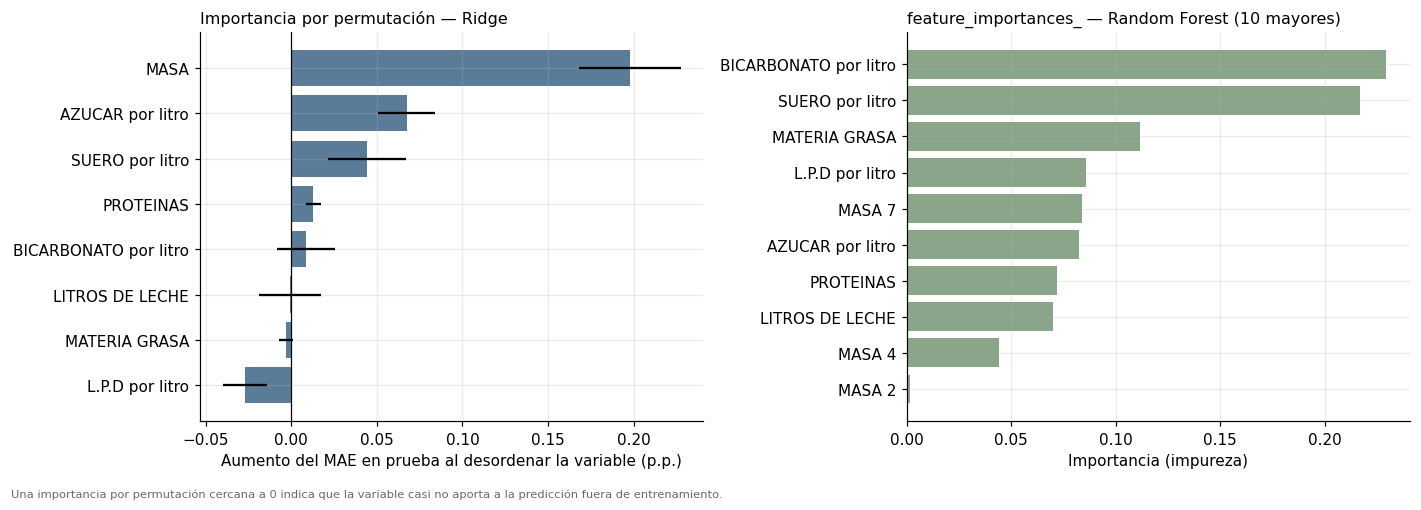

,Variable,Aumento del MAE (p.p.),Desvío
0,MASA,0.1976,0.0298
2,AZUCAR por litro,0.0675,0.0165
3,SUERO por litro,0.0444,0.0227
7,PROTEINAS,0.0130,0.0042
4,BICARBONATO por litro,0.0087,0.0169
1,LITROS DE LECHE,-0.0006,0.0182
6,MATERIA GRASA,-0.0029,0.0042
5,L.P.D por litro,-0.0270,0.0129


In [14]:
pi = permutation_importance(m_el, Xte, yte, scoring='neg_mean_absolute_error', n_repeats=30, random_state=SEMILLA, n_jobs=1)
imp = pd.DataFrame({'Variable': VARIABLES, 'Aumento del MAE (p.p.)': pi.importances_mean, 'Desvío': pi.importances_std}).sort_values('Aumento del MAE (p.p.)')
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
ax[0].barh(imp['Variable'], imp['Aumento del MAE (p.p.)'], xerr=imp['Desvío'], color='#5B7C99'); ax[0].axvline(0, color='black', lw=.8)
ax[0].set_title(f'Importancia por permutación — {elegido}', loc='left', fontsize=10.5); ax[0].set_xlabel('Aumento del MAE en prueba al desordenar la variable (p.p.)')
rf = modelos['Random Forest']; nombres_f = rf.named_steps['preparar'].get_feature_names_out()
fi = pd.Series(rf.named_steps['modelo'].feature_importances_, index=[s.replace('num__', '').replace('masa__MASA_', '') for s in nombres_f]).sort_values().tail(10)
ax[1].barh(fi.index, fi.values, color='#8AA58A'); ax[1].set_title('feature_importances_ — Random Forest (10 mayores)', loc='left', fontsize=10.5); ax[1].set_xlabel('Importancia (impureza)')
fig.text(.01, .005, 'Una importancia por permutación cercana a 0 indica que la variable casi no aporta a la predicción fuera de entrenamiento.', fontsize=7.5, color='dimgray')
plt.tight_layout(rect=(0, .03, 1, 1)); plt.savefig(FIG / 'fig5_importancia.png', dpi=150); plt.show()
display(imp.sort_values('Aumento del MAE (p.p.)', ascending=False).round(4))

### Curva de aprendizaje del modelo elegido
Como los datos son temporales, se entrena con prefijos cronológicos del entrenamiento (20 %, 40 %, …, 100 %) y se mide el error en esos mismos datos y en la prueba.

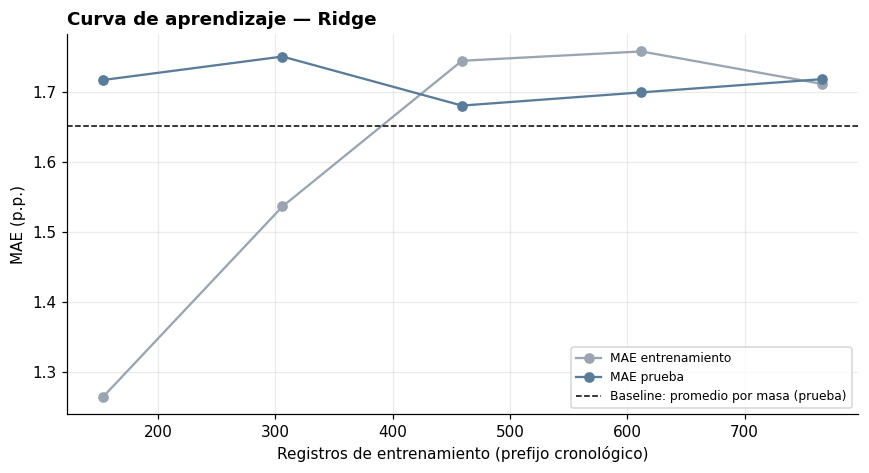

 n entrenamiento  MAE entren.  MAE prueba
             153        1.264       1.717
             306        1.536       1.751
             459        1.745       1.681
             612        1.758       1.700
             766        1.712       1.719


In [15]:
fracs = [.2, .4, .6, .8, 1.0]; ns, e_tr, e_te = [], [], []
for f in fracs:
    n = int(len(train) * f); m = clone(m_el).fit(Xtr.iloc[:n], ytr.iloc[:n])
    ns.append(n); e_tr.append(mean_absolute_error(ytr.iloc[:n], m.predict(Xtr.iloc[:n]))); e_te.append(mean_absolute_error(yte, m.predict(Xte)))
ref = mae_te['Base: promedio por masa']
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.plot(ns, e_tr, 'o-', label='MAE entrenamiento', color='#9AA5B1'); ax.plot(ns, e_te, 'o-', label='MAE prueba', color='#5B7C99')
ax.axhline(ref, ls='--', color='black', lw=1, label='Baseline: promedio por masa (prueba)')
ax.set_xlabel('Registros de entrenamiento (prefijo cronológico)'); ax.set_ylabel('MAE (p.p.)'); ax.set_title(f'Curva de aprendizaje — {elegido}', loc='left', fontweight='bold'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / 'fig6_curva_aprendizaje.png', dpi=150); plt.show()
print(pd.DataFrame({'n entrenamiento': ns, 'MAE entren.': np.round(e_tr, 3), 'MAE prueba': np.round(e_te, 3)}).to_string(index=False))

### Análisis de sensibilidad a registros extremos
Existen registros con desvíos extremos (|desvío| > 25 p.p.) que parecen errores de carga. Se repite el entrenamiento **con los mismos hiperparámetros elegidos** sin esos registros, para ver si las conclusiones dependen de ellos.

In [16]:
extremos = (desarrollo['DESVIO_PP'].abs() > 25)
print('Registros extremos excluidos en la sensibilidad:', int(extremos.sum()), '| en entrenamiento:', int(extremos.iloc[:k].sum()), '| en prueba:', int(extremos.iloc[k:].sum()))
tr2, te2 = train[~extremos.iloc[:k].values], test[~extremos.iloc[k:].values]
filas = []
for n in nombres:
    m = clone(modelos[n]).fit(tr2[VARIABLES], tr2['DESVIO_PP']); p = m.predict(te2[VARIABLES])
    filas.append({'Modelo': n, 'MAE prueba (principal)': mae_te[n], 'MAE prueba (sin extremos)': mean_absolute_error(te2['DESVIO_PP'], p),
                  'R² prueba (principal)': r2_score(yte, pred_te[n]), 'R² prueba (sin extremos)': r2_score(te2['DESVIO_PP'], p)})
display(pd.DataFrame(filas).round(3))

Registros extremos excluidos en la sensibilidad: 2 | en entrenamiento: 2 | en prueba: 0


,Modelo,MAE prueba (principal),MAE prueba (sin extremos),R² prueba (principal),R² prueba (sin extremos)
0,Base: promedio por masa,1.651,1.678,0.057,0.037
1,Base: regresión lineal,2.092,2.087,-1.749,-1.487
2,Ridge,1.719,1.744,0.036,0.025
3,Árbol de decisión,1.711,1.725,0.018,0.003
4,Random Forest,1.732,1.726,0.009,0.010


## Resumen de resultados (se calcula a partir de las celdas anteriores)

In [17]:
b = mae_te['Base: promedio por masa']; l = mae_te['Base: regresión lineal']
print(f'1) Partición: {len(train)} entrenamiento / {len(test)} prueba (70/30 cronológico), semilla {SEMILLA}, validación cruzada temporal de 5 pliegues.')
print(f'2) Modelo elegido por MAE CV: {elegido} (MAE CV {cv_mae[elegido]:.3f}; MAE prueba {mae_te[elegido]:.3f}; R² prueba {r2_score(yte, pred_te[elegido]):.3f}).')
print(f'3) Baselines en prueba: promedio por masa MAE {b:.3f}; regresión lineal MAE {l:.3f}.')
print(f'4) Diferencia entre el mejor algoritmo en prueba y el promedio por masa: {b - min(mae_te[n] for n in algoritmos):+.3f} p.p.')
print('5) Diagnóstico:', {r["Modelo"]: r["Diagnóstico"] for _, r in diagnostico.iterrows()})

1) Partición: 766 entrenamiento / 328 prueba (70/30 cronológico), semilla 42, validación cruzada temporal de 5 pliegues.
2) Modelo elegido por MAE CV: Ridge (MAE CV 1.909; MAE prueba 1.719; R² prueba 0.036).
3) Baselines en prueba: promedio por masa MAE 1.651; regresión lineal MAE 2.092.
4) Diferencia entre el mejor algoritmo en prueba y el promedio por masa: -0.060 p.p.
5) Diagnóstico: {'Base: promedio por masa': 'subajuste / alto sesgo (R² bajo en ambos conjuntos)', 'Base: regresión lineal': 'sobreajuste / alta varianza (rinde mucho peor en prueba que en entrenamiento)', 'Ridge': 'subajuste / alto sesgo (R² bajo en ambos conjuntos)', 'Árbol de decisión': 'subajuste / alto sesgo (R² bajo en ambos conjuntos)', 'Random Forest': 'sobreajuste / alta varianza (rinde mucho peor en prueba que en entrenamiento)'}


## Conclusiones (interpretar con la nueva partición)
- Se eligió el modelo por **MAE de validación cruzada temporal**, sin utilizar la prueba ni las diez elaboraciones reservadas.
- Se reporta también el **promedio histórico por masa** como referencia: si es mejor que el modelo seleccionado, debe reconocerse explícitamente.
- Los errores se presentan en **puntos porcentuales**. Estos resultados indican asociación y capacidad predictiva, no causas del bajo rendimiento.
- Las diez elaboraciones reservadas permiten una demostración rigurosa y repetible en Streamlit. El sorteo puede seleccionar una al azar sin mostrar su valor real hasta el final.
- Las cifras deben tomarse de las tablas generadas por **esta ejecución**; no de notebooks anteriores con otras particiones.

## Demostración en Streamlit: diez elaboraciones
La aplicación **App 2** permite sortear sin repetición uno de los diez registros separados, usar el modelo serializado y comparar predicción versus desvío real solo al presionar **Revelar resultado**. Las diez elaboraciones no afectan el entrenamiento, la validación cruzada, la elección de hiperparámetros ni la evaluación final.

**Privacidad:** ejecutar únicamente en `127.0.0.1`; no publicar los JSON (que contienen resultados reales) ni el Excel.

In [18]:
# ---------- Exportación para App 2 (10 elaboraciones excluidas de todas las fases) ----------
joblib.dump(modelos[elegido], 'modelo_TP2.joblib')

def convertir(v):
    if hasattr(v,'item'): v=v.item()
    return v

casos = []
resultados = []
for i, (_, r) in enumerate(reservado.iterrows(), 1):
    eid = f'E{i:02d}'
    casos.append({
        'id': eid, 'fecha': str(r['FECHA ELABORACION'].date()),
        'lote': str(r['Nº LOTE DDL']), 'masa': str(r['MASA']),
        'entradas': {c: convertir(r[c]) if pd.notna(r[c]) else None for c in VARIABLES}
    })
    resultados.append({'id': eid, 'desvio_real_pp': float(r['DESVIO_PP'])})

with open('registros_demo_TP2_10.json','w',encoding='utf-8') as f:
    json.dump(casos,f,ensure_ascii=False,indent=2,allow_nan=False)
with open('resultados_demo_TP2_10.json','w',encoding='utf-8') as f:
    json.dump(resultados,f,ensure_ascii=False,indent=2,allow_nan=False)
with open('resumen_TP2_10.json','w',encoding='utf-8') as f:
    json.dump({
       'ganador':elegido,'criterio':'MAE CV temporal (menor es mejor)',
       'mae_referencia':float(mae_te['Base: promedio por masa']),
       'comparacion':[{'Algoritmo':n,'MAE CV (p.p.)':float(cv_mae[n]),'MAE prueba (p.p.)':float(mae_te[n]),
                       'RMSE prueba (p.p.)':float(np.sqrt(mean_squared_error(yte,pred_te[n]))),
                       'R² prueba':float(r2_score(yte,pred_te[n])),
                       'Mejores parámetros':str(busquedas[n].best_params_)} for n in algoritmos],
       'n_entrenamiento':len(train),'n_prueba':len(test),'n_reservadas':len(reservado),
       'variables':VARIABLES,
    },f,ensure_ascii=False,indent=2)
assert len(casos)==len(resultados)==10
print('Archivos: modelo_TP2.joblib, registros_demo_TP2_10.json, resultados_demo_TP2_10.json, resumen_TP2_10.json')

Archivos: modelo_TP2.joblib, registros_demo_TP2_10.json, resultados_demo_TP2_10.json, resumen_TP2_10.json
